#Caso Práctico Unidad 1

## Ejercicio 1

### Importación de datos

In [8]:
import datetime
import pandas as pd
import plotly.express as px

data_path = "AirPassengers.csv"

df = pd.read_csv(data_path)

months = []

for row in range(df.shape[0]):
    months.append(datetime.datetime.strptime(df['Month'].iloc[row], '%Y-%m'))

df['Fecha'] = months

df.head()

,Month,#Passengers,Fecha
0,1949-01,112,1949-01-01
1,1949-02,118,1949-02-01
2,1949-03,132,1949-03-01
3,1949-04,129,1949-04-01
4,1949-05,121,1949-05-01


In [9]:
df['Pasajeros'] = df['#Passengers']
df['Tiempo'] = df.index

fig = px.line(
    df,
    x=df['Fecha'],
    y=df['Pasajeros'],
    markers=True,
    labels={"x": "Fecha", "y": "Pasajeros"},
    title="Air Passengers"
)

fig.show()

La serie muestra una tendencia creciente clara a lo largo del tiempo. También se observa cierta estacionalidad, con patrones que se repiten periódicamente. Esto sugiere que la serie no es estacionaria.

### Autocorrelacion

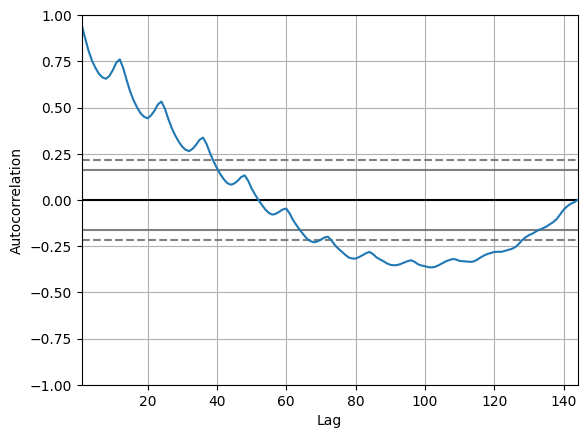

In [10]:
from matplotlib import pyplot

pd.plotting.autocorrelation_plot(df['Pasajeros'])
pyplot.show()

La autocorrelación presenta valores altos en los primeros retardos. Esto indica una fuerte dependencia temporal entre los datos. La caída progresiva sugiere la presencia de tendencia en la serie.

In [11]:
import statsmodels.api as sm
import plotly.graph_objects as go
from plotly.subplots import make_subplots

acorr = sm.tsa.acf(df['Pasajeros'], nlags=80)
pacorr = sm.tsa.pacf(df['Pasajeros'], nlags=10)

fig = make_subplots(
    rows=1,
    cols=1,
    shared_xaxes=False,
    shared_yaxes=True,
    vertical_spacing=0.08,
)

fig.add_trace(
    go.Scatter(
        y=pacorr,
        name="Autocorrelación",
        mode="markers+lines"
    ),
    row=1,
    col=1
)

fig.add_hline(y=0.5, row=1, col=1, line_dash="dash")

fig.update_layout(
    height=500,
    width=500,
    title_text="Autocorrelación Parcial"
)

fig['layout']['xaxis1']['title'] = 'Retardo (Intervalos)'
fig.show()

La PACF muestra picos significativos en los primeros retardos. Esto ayuda a identificar el posible orden del componente autorregresivo (AR). Se observa que pocos retardos explican gran parte de la dependencia.

In [12]:
df['Diferenciación'] = df['Pasajeros'].diff(periods=1)
df['Diferenciación_2'] = df['Diferenciación'].diff(periods=1)
df['Diferenciación_3'] = df['Diferenciación_2'].diff(periods=1)


fig = make_subplots(rows=3, cols=1,
                    shared_xaxes=False,
                    shared_yaxes=True,
                    vertical_spacing=0.08,
                    )

fig.add_trace(go.Scatter(y=df['Diferenciación'], name="Orden 1", mode="markers+lines"),
              row=1, col=1)

fig.add_trace(go.Scatter(y=df['Diferenciación_2'], name="Orden 2", mode="markers+lines"),
              row=2, col=1)

fig.add_trace(go.Scatter(y=df['Diferenciación_3'], name="Orden 3", mode="markers+lines"),
              row=3, col=1)

fig.update_layout(height=500, width=900,
                  title_text="Diferenciación"
                  )

fig['layout']['xaxis1']['title']=''
fig['layout']['xaxis2']['title']=''

fig.show()

Tras aplicar la diferenciación, la serie pierde la tendencia. La variabilidad parece más constante, lo que indica que la serie se aproxima a la estacionariedad.

### Test estadístico para asumir estacionariedad

In [16]:
from statsmodels.tsa.stattools import adfuller

X = df['Diferenciación'].values
result = adfuller(X[1:])
print('ADF Statistic: %f' % result[0])
print('p-value: %f' % result[1])
print('Critical Values:')
for key, value in result[4].items():
 print('\t%s: %.3f' % (key, value))

ADF Statistic: -2.829267
p-value: 0.054213
Critical Values:
	1%: -3.482
	5%: -2.884
	10%: -2.579


In [17]:
X = df['Diferenciación_2'].values
result = adfuller(X[2:])
print('ADF Statistic: %f' % result[0])
print('p-value: %f' % result[1])
print('Critical Values:')
for key, value in result[4].items():
 print('\t%s: %.3f' % (key, value))

ADF Statistic: -16.384232
p-value: 0.000000
Critical Values:
	1%: -3.482
	5%: -2.884
	10%: -2.579


In [18]:
X = df['Diferenciación_3'].values
result = adfuller(X[3:])
print('ADF Statistic: %f' % result[0])
print('p-value: %f' % result[1])
print('Critical Values:')
for key, value in result[4].items():
 print('\t%s: %.3f' % (key, value))

ADF Statistic: -9.434675
p-value: 0.000000
Critical Values:
	1%: -3.483
	5%: -2.885
	10%: -2.579


El p-value obtenido es bajo, lo que permite rechazar la hipótesis nula. Esto indica que la serie diferenciada puede considerarse estacionaria.

### Aplicación de ARIMA

In [21]:
from pandas import read_csv
from datetime import datetime
from matplotlib import pyplot
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error
from math import sqrt

"""
Cargamos el conjunto de Datos
"""

def parser(x):
    return datetime.strptime(x, '%Y-%m')

series = read_csv(data_path, header=0, index_col=0,
                  parse_dates=True,
                  date_parser=parser)

series = series.iloc[:, 0]   #sustituye a squeeze=True


"""
Ajustamos es índice temporal de los datos
"""

series.index = series.index.to_period('M')


"""
Separamos los datos para obtener un conjunto de entrenamiento
y otro conjunto de test
"""

X = series.values
size = int(len(X) * 0.60)
train, test = X[0:size], X[size:len(X)]
history = [x for x in train]
predictions = list()

/tmp/ipykernel_7474/2747606853.py:15: FutureWarning:

The argument 'date_parser' is deprecated and will be removed in a future version. Please use 'date_format' instead, or read your data in as 'object' dtype and then call 'to_datetime'.



In [22]:
fig = make_subplots(rows=1, cols=1,
                    shared_xaxes=False,
                    shared_yaxes=True,
                    vertical_spacing=0.08,
                    )

fig.add_trace(go.Scatter(x=df['Fecha'][:len(train)], y=train.flatten(), name="Ajuste", mode="markers+lines"),
              row=1, col=1)

fig.add_trace(go.Scatter(x=df['Fecha'][len(train):], y=test.flatten(), name="Test", mode="markers+lines"),
              row=1, col=1)

fig.update_layout(height=500, width=900,
                  title_text="Separación de conjunto de datos"
                  )

fig['layout']['xaxis1']['title']=''
fig['layout']['yaxis1']['title']='Pasajeros'

fig.show()

El conjunto de test sigue el mismo patrón que el de entrenamiento, lo que permite validar correctamente el modelo.

In [23]:
"""
Ajuste del modelo ARIMA con los datos de entrenamiento
"""

for t in range(len(test)):
    model = ARIMA(history, order=(5,1,3))
    model_fit = model.fit()
    output = model_fit.forecast()
    yhat = output[0]
    predictions.append(yhat)
    obs = test[t]
    history.append(obs)
    print('predicted=%f, expected=%f' % (yhat, obs))


"""
Calculamos el error que comete el modelo ARIMA para el conjunto de test
"""

rmse = sqrt(mean_squared_error(test, predictions))
print('Test RMSE: %.3f' % rmse)

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning:

Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning:

Non-invertible starting MA parameters found. Using zeros as starting parameters.

/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals



predicted=291.323075, expected=317.000000


/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals



predicted=333.001596, expected=313.000000


/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals



...

/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals



predicted=354.989244, expected=362.000000


/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals



predicted=375.524483, expected=405.000000
predicted=440.815246, expected=417.000000
predicted=412.952987, expected=391.000000
predicted=411.992524, expected=419.000000
predicted=402.596718, expected=461.000000
predicted=504.785258, expected=472.000000
predicted=437.827168, expected=535.000000
predicted=552.374252, expected=622.000000
predicted=609.819415, expected=606.000000
predicted=564.482322, expected=508.000000
predicted=444.562037, expected=461.000000
predicted=436.493060, expected=390.000000
predicted=387.063006, expected=432.000000
Test RMSE: 38.897


/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals



El modelo ARIMA permite generar predicciones que siguen en términos generales la evolución de la serie, aunque se observan diferencias entre los valores predichos y los reales en varios puntos. El valor del RMSE indica un error moderado, por lo que el modelo es capaz de captar la tendencia global pero no ajusta perfectamente las fluctuaciones. Además, el aviso de convergencia sugiere que el modelo podría mejorarse ajustando sus parámetros para obtener un mejor rendimiento.

In [24]:
fig = make_subplots(rows=1, cols=1,
                    shared_xaxes=False,
                    shared_yaxes=True,
                    vertical_spacing=0.08,
                    )

fig.add_trace(go.Scatter(x=df['Fecha'][-len(test):], y=test.flatten(), name="Valor Real", mode="markers+lines"),
              row=1, col=1)

fig.add_trace(go.Scatter(x=df['Fecha'][-len(test):], y=predictions, name="Predicción", mode="markers+lines"),
              row=1, col=1)

fig.update_layout(height=500, width=900,
                  title_text="Evaluación"
                  )

fig['layout']['xaxis1']['title']=''
fig['layout']['yaxis1']['title']='Pasajeros'

fig.show()

En la gráfica se observa que las predicciones siguen de forma bastante cercana la evolución de los valores reales, reproduciendo tanto la tendencia creciente como los patrones estacionales de la serie. No obstante, existen algunas desviaciones puntuales, especialmente en los picos y valles, donde el modelo no ajusta con total precisión.